<a href="https://colab.research.google.com/github/Lorenzito/ProgramacionParaAnaliticaDescriptivayPredicitva/blob/main/ArbolDecision_Glioma_273524.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 1: Árbol de Decisión con Validación Cruzada y Optimización de Hiperparámetros
### Programación para Analítica Descriptiva y Predictiva · Semana 13 · Práctica 01
**Dataset:** Glioma Grading Clinical and Mutation Features (UCI Machine Learning Repository)

| | |
|---|---|
| **Nombre:** | Lorenzo Varela Ollervides |
| **Matrícula:** | 273524 |
| **Fecha:** | 9 de noviembre de 2026 |

**Objetivo:** aplicar de forma integral el proceso de entrenamiento, ajuste y evaluación de un clasificador tipo Árbol de Decisión, usando validación cruzada estratificada y optimización de hiperparámetros con `RandomizedSearchCV` y `GridSearchCV`.

---
## 1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos

En esta sección se declaran las bibliotecas que se usan en todo el cuaderno y se carga el conjunto de datos *Glioma Grading Clinical and Mutation Features* directamente desde el repositorio de UCI.

In [1]:
# 1.1 Bibliotecas
# Librerías para manejar los datos y hacer las gráficas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo de árbol de decisión para clasificación
from sklearn.tree import DecisionTreeClassifier

# Validación cruzada estratificada y funciones para evaluar un modelo con ella
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate

# Métodos de optimización de hiperparámetros
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Distribución de enteros para definir el espacio de búsqueda aleatorio
from scipy.stats import randint

# Para que las tablas muestren todas las columnas y no las corten con "..."
pd.set_option('display.max_columns', None)

print('Configuración completada. Todas las librerías importadas correctamente.')

Configuración completada. Todas las librerías importadas correctamente.


In [2]:
# 1.2 Carga del conjunto de datos
# pandas lee el archivo CSV directamente desde la dirección del repositorio de UCI
# (el 759 es el identificador del dataset Glioma Grading Clinical and Mutation Features)
url = "https://archive.ics.uci.edu/static/public/759/data.csv"
df = pd.read_csv(url)

# Primeras filas para ver cómo vienen los datos
print("\n --- Vista Inicial ---")
df.head()


 --- Vista Inicial ---


,Case_ID,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Grade
0,TCGA-DU-8164,0,51.30,white,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
1,TCGA-QH-A6CY,0,38.72,white,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,TCGA-HW-A5KM,0,35.17,white,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,TCGA-E1-A7YE,1,32.78,white,1,1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0
4,TCGA-S9-A6WG,0,31.51,white,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


---
## 2. Análisis exploratorio de datos (EDA)

Antes de modelar se hace un análisis inicial de los datos: forma y estructura (`shape`, `info()`, `describe()`), distribución de clases (`y.value_counts()`), histogramas de tres variables numéricas, un boxplot por clase y el mapa de calor de correlaciones entre variables.

In [3]:
# 2.1 Forma y estructura del dataset
# shape da el tamaño e info() el tipo de dato de cada columna y si hay nulos
print("\n --- Inspección Estructural ---")
print("Shape:", df.shape)
df.info()


 --- Inspección Estructural ---
Shape: (839, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Case_ID           839 non-null    object 
 1   Gender            839 non-null    int64  
 2   Age_at_diagnosis  839 non-null    float64
 3   Race              839 non-null    object 
 4   IDH1              839 non-null    int64  
 5   TP53              839 non-null    int64  
 6   ATRX              839 non-null    int64  
 7   PTEN              839 non-null    int64  
 8   EGFR              839 non-null    int64  
 9   CIC               839 non-null    int64  
 10  MUC16             839 non-null    int64  
 11  PIK3CA            839 non-null    int64  
 12  NF1               839 non-null    int64  
 13  PIK3R1            839 non-null    int64  
 14  FUBP1             839 non-null    int64  
 15  RB1               839 non-null    int64  

In [4]:
# 2.2 Estadísticas descriptivas
# describe() da conteo, media, desviación estándar, mínimo, cuartiles y máximo
# de las columnas numéricas
print("\n --- Estadísticas Descriptivas Básicas ---")
df.describe()


 --- Estadísticas Descriptivas Básicas ---


,Gender,Age_at_diagnosis,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Grade
count,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000
mean,0.418355,50.935411,0.481526,0.414779,0.258641,0.168057,0.133492,0.132300,0.116806,0.087008,0.079857,0.064362,0.053635,0.047676,0.045292,0.034565,0.032181,0.032181,0.032181,0.027414,0.027414,0.026222,0.419547
std,0.493583,15.702339,0.499957,0.492978,0.438149,0.374140,0.340309,0.339019,0.321380,0.282015,0.271233,0.245544,0.225431,0.213206,0.208068,0.182784,0.176586,0.176586,0.176586,0.163383,0.163383,0.159889,0.493779
min,0.000000,14.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,38.055000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,51.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,62.800000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,1.000000,89.290000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Variables predictoras (X) y variable objetivo (y)

Con `info()` se ve que hay dos columnas de texto: `Case_ID` y `Race`. El árbol de decisión de scikit-learn solo trabaja con números, así que antes de seguir se preparan los datos:

- `y` es la columna `Grade`, la clase a predecir (según la página del dataset en UCI, 0 = LGG y 1 = GBM).
- `Case_ID` es el identificador de cada paciente, por lo que no se usa como variable predictora.
- `Race` se convierte a columnas numéricas 0/1 con `pd.get_dummies`, una por categoría.

In [5]:
# 2.3 Variables predictoras (X) y variable objetivo (y)
# y: la clase a predecir
y = df['Grade']

# X: se quitan Grade (es la variable objetivo) y Case_ID (es un identificador)
X = df.drop(columns=['Grade', 'Case_ID'])

# Categorías de Race antes de codificarla
print("Categorías de Race:")
print(X['Race'].value_counts())

# One-hot encoding con pandas: una columna por cada categoría de Race
X = pd.get_dummies(X, columns=['Race'])

# get_dummies deja valores True/False, así que se convierten a 1/0
columnas_race = [col for col in X.columns if col.startswith('Race_')]
X[columnas_race] = X[columnas_race].astype(int)

print("\nX:", X.shape)
print("y:", y.shape)
X.head()

Categorías de Race:
Race
white                               765
black or african american            59
asian                                14
american indian or alaska native      1
Name: count, dtype: int64

X: (839, 26)
y: (839,)


,Gender,Age_at_diagnosis,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Race_american indian or alaska native,Race_asian,Race_black or african american,Race_white
0,0,51.30,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
1,0,38.72,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,0,35.17,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,1,32.78,1,1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1
4,0,31.51,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [6]:
# 2.4 Distribución de clases
# value_counts() cuenta cuántas observaciones hay de cada clase (0 = LGG, 1 = GBM)
print("\n --- Distribución de clases ---")
print(y.value_counts())


 --- Distribución de clases ---
Grade
0    487
1    352
Name: count, dtype: int64


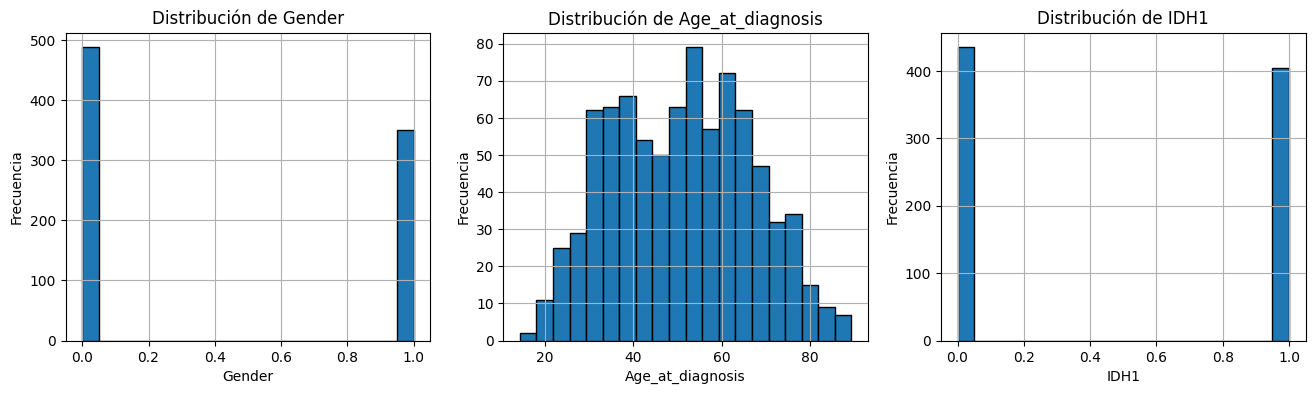

In [7]:
# 2.5 Histogramas de tres variables numéricas
# Se toman las tres primeras columnas numéricas del dataset
variables_hist = ['Gender', 'Age_at_diagnosis', 'IDH1']

# Una gráfica por variable, en una sola fila
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, variable in zip(axes, variables_hist):
    ax.hist(df[variable], bins=20, edgecolor='black')
    ax.set_title(f"Distribución de {variable}")
    ax.set_xlabel(variable)
    ax.set_ylabel("Frecuencia")
    ax.grid(True)
plt.show()

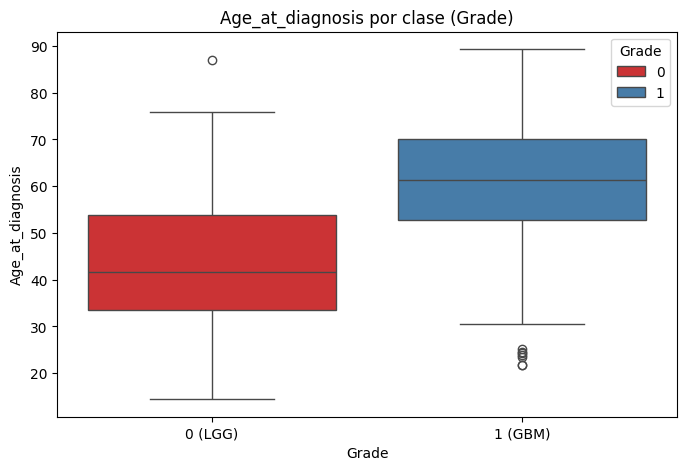

In [8]:
# 2.6 Boxplot por clase
# Age_at_diagnosis es la única variable continua, así que es la que se compara
# entre las dos clases de Grade
plt.figure(figsize=(8, 5))
sns.boxplot(x='Grade', y='Age_at_diagnosis', hue='Grade', data=df, palette='Set1')
plt.xticks(ticks=[0, 1], labels=['0 (LGG)', '1 (GBM)'])
plt.title('Age_at_diagnosis por clase (Grade)')
plt.xlabel('Grade')
plt.ylabel('Age_at_diagnosis')
plt.show()

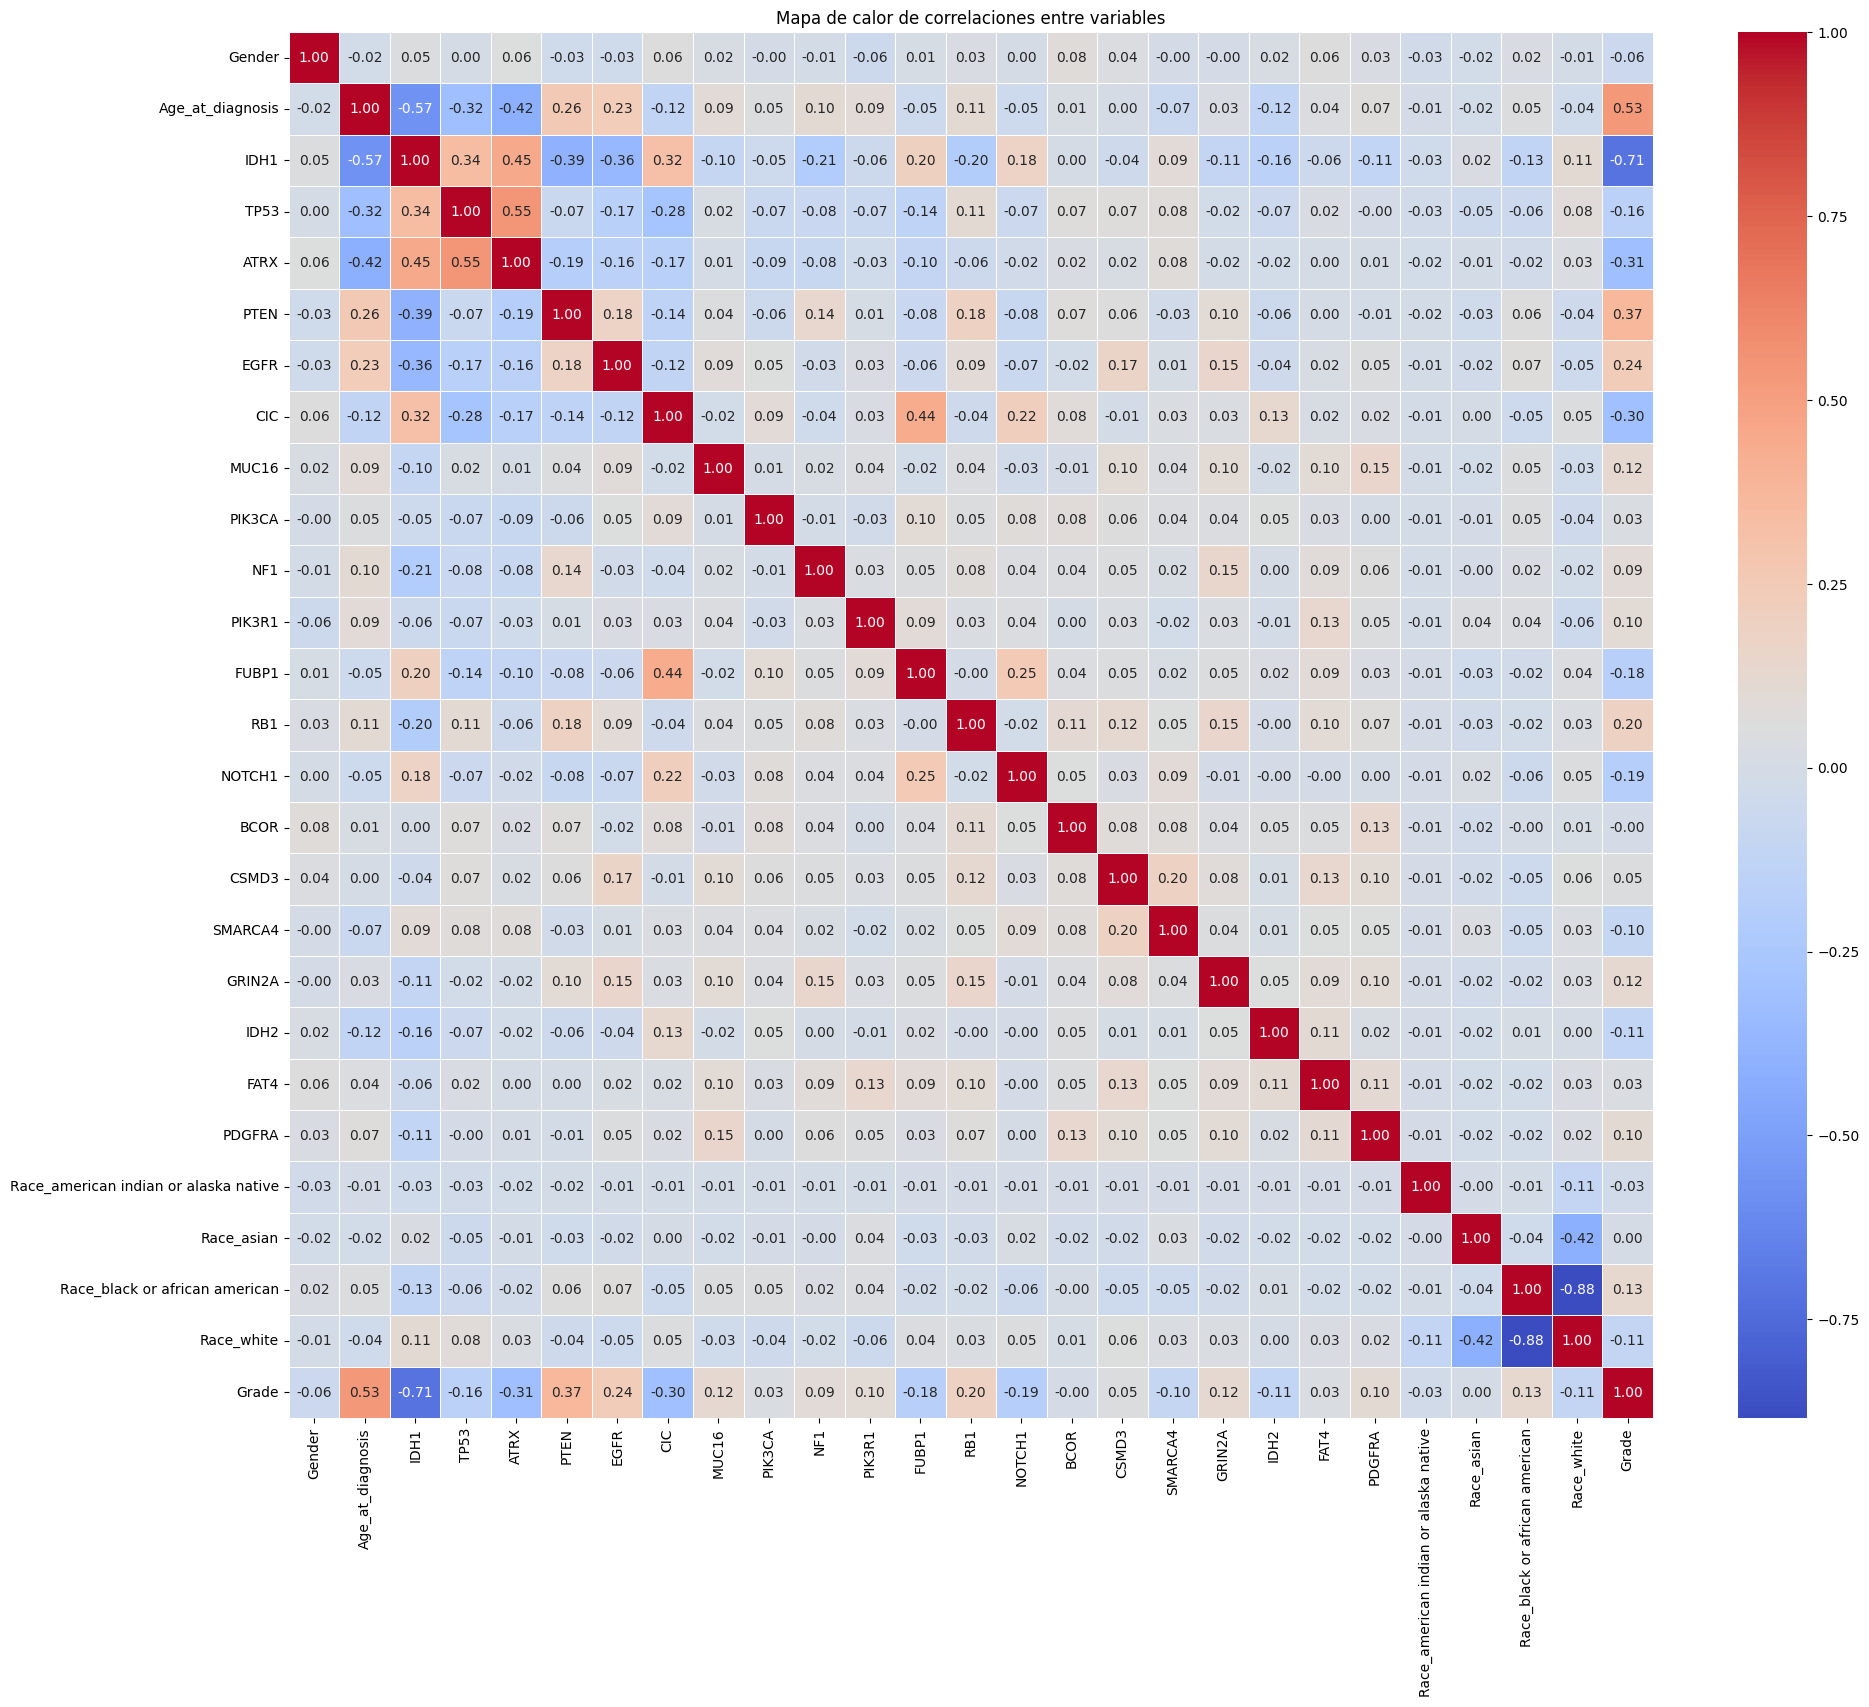

In [9]:
# 2.7 Mapa de calor de correlaciones entre variables
# Se juntan X (ya con Race codificada) y y para incluir también la correlación
# de cada variable con la clase Grade
datos_corr = pd.concat([X, y], axis=1)
correlation_matrix = datos_corr.corr()

plt.figure(figsize=(22, 18))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title("Mapa de calor de correlaciones entre variables")
plt.show()

### Interpretación de la sección 2

El dataset tiene 839 filas y 25 columnas, sin valores nulos (todas las columnas tienen 839 datos). De las 25 columnas, 22 son enteras, una es decimal (`Age_at_diagnosis`) y dos son de texto (`Case_ID` y `Race`). Después de quitar `Case_ID` y `Grade` y de codificar `Race` en cuatro columnas (una por cada categoría: white con 765 casos, black or african american con 59, asian con 14 y american indian or alaska native con 1), `X` quedó con 839 filas y 26 variables predictoras, y `y` con los 839 valores de `Grade`.

En `describe()` se ve que `Age_at_diagnosis` va de 14.42 a 89.29 años, con media de 50.94 y mediana de 51.55. El resto de las columnas numéricas solo toma los valores 0 y 1, así que su media indica la proporción de casos con valor 1: las mutaciones más frecuentes son `IDH1` (0.4815), `TP53` (0.4148) y `ATRX` (0.2586), mientras que las demás están por debajo de 0.17 y la menos frecuente es `PDGFRA` (0.0262).

En los histogramas, `Age_at_diagnosis` es la única de las tres variables con una distribución continua: las edades se reparten en todo el rango, con la mayoría de los casos más o menos entre los 30 y los 70 años. `Gender` e `IDH1` solo tienen dos barras (0 y 1) porque son binarias; en las dos la barra del 0 es la más alta, lo que coincide con sus medias de 0.4184 y 0.4815.

En el boxplot se ve que la edad al diagnóstico es distinta entre las dos clases: en la clase 0 (LGG) la mediana está un poco arriba de los 40 años y en la clase 1 (GBM) está alrededor de los 60. Las cajas casi no se traslapan, porque la parte alta de la caja de la clase 0 queda cerca de donde empieza la caja de la clase 1.

### Reflexión

**¿Existen clases desbalanceadas?**

**Respuesta:** Hay un desbalance ligero. Con `y.value_counts()` se obtienen 487 casos de la clase 0 (LGG) y 352 de la clase 1 (GBM), que sobre los 839 casos equivalen a 58.0% y 42.0%. La clase 0 es la mayoritaria, pero la diferencia es de 135 casos y ninguna de las dos clases queda con pocos datos, así que no es un desbalance fuerte.

**¿Qué atributos parecen más informativos?**

**Respuesta:** Según el mapa de calor, los atributos con la correlación más alta con `Grade` (en valor absoluto) son:

- `IDH1` (-0.71): es la relación más fuerte, y es negativa, o sea que la mutación aparece sobre todo en la clase 0.
- `Age_at_diagnosis` (0.53): a mayor edad, más casos de la clase 1, que es lo mismo que se vio en el boxplot.
- `PTEN` (0.37), `ATRX` (-0.31) y `CIC` (-0.30), y un poco más abajo `EGFR` (0.24) y `RB1` (0.20).

En cambio, atributos como `Gender` (-0.06), `PIK3CA` (0.03), `FAT4` (0.03), `BCOR` (-0.00) o `Race_asian` (0.00) casi no tienen relación lineal con la clase.

También hay correlación entre algunas variables predictoras: `Race_white` con `Race_black or african american` (-0.88), que es de esperarse porque salen de la misma variable `Race`; `IDH1` con `Age_at_diagnosis` (-0.57); `ATRX` con `TP53` (0.55), y `CIC` con `FUBP1` (0.44).

---
## 3. Gráfica de Errores en Entrenamiento y Prueba

Se entrena un árbol de decisión con las profundidades 2, 5, 10, 15, 20, 25, 30 y `None`, y cada una se evalúa con validación cruzada estratificada de 10 particiones (`StratifiedKFold`) usando F1 Macro como métrica.

- El `StratifiedKFold` usa 10 particiones y valor aleatorio 3.
- El árbol usa valor aleatorio 7.
- El F1 Macro de prueba se obtiene con `cross_val_score`. Como esa función solo regresa el puntaje de prueba de cada partición, el de entrenamiento se obtiene con `cross_validate` (con `return_train_score=True`), usando el mismo modelo y las mismas particiones.

In [10]:
# 3.1 Árboles con distintas profundidades evaluados con Stratified 10-Fold
# Profundidades a evaluar (None = el árbol crece sin límite)
depths = [2, 5, 10, 15, 20, 25, 30, None]

# Validación cruzada estratificada: 10 particiones y valor aleatorio 3
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

f1_train = []
f1_test = []

for depth in depths:
    # Árbol con la profundidad que toca y valor aleatorio 7
    clf = DecisionTreeClassifier(max_depth=depth, random_state=7)

    # F1 Macro en prueba: cross_val_score regresa un valor por partición
    # y se guarda el promedio de las 10
    scores = cross_val_score(clf, X, y, cv=skf, scoring='f1_macro')
    f1_test.append(scores.mean())

    # F1 Macro en entrenamiento: cross_validate con return_train_score=True
    # regresa también el puntaje sobre los datos con los que se entrenó cada partición
    results = cross_validate(clf, X, y, cv=skf, scoring='f1_macro', return_train_score=True)
    f1_train.append(results['train_score'].mean())

# Etiquetas de las profundidades como texto, para poder mostrar también None
etiquetas = [str(depth) for depth in depths]

# Tabla con los resultados de cada profundidad
resultados_prof = pd.DataFrame({
    'max_depth': etiquetas,
    'F1_macro_train': f1_train,
    'F1_macro_test': f1_test
})
resultados_prof

,max_depth,F1_macro_train,F1_macro_test
0,2,0.869106,0.866538
1,5,0.885855,0.857712
2,10,0.928534,0.821592
3,15,0.974421,0.800457
4,20,0.994717,0.793204
5,25,0.998642,0.791879
6,30,0.999864,0.791711
7,None,1.000000,0.789046


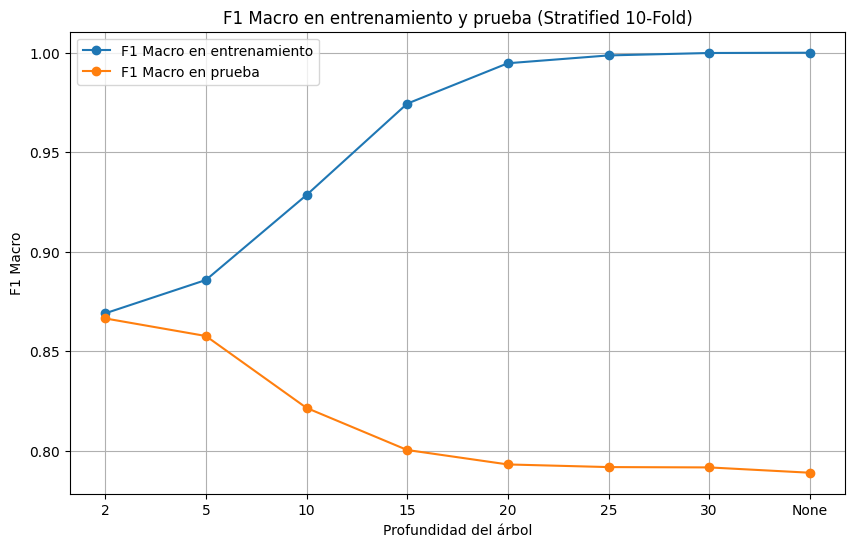

In [11]:
# 3.2 Gráfica del F1 Macro en entrenamiento y prueba según la profundidad
plt.figure(figsize=(10, 6))
plt.plot(etiquetas, f1_train, label='F1 Macro en entrenamiento', marker='o')
plt.plot(etiquetas, f1_test, label='F1 Macro en prueba', marker='o')
plt.xlabel('Profundidad del árbol')
plt.ylabel('F1 Macro')
plt.title('F1 Macro en entrenamiento y prueba (Stratified 10-Fold)')
plt.legend()
plt.grid(True)
plt.show()

### Análisis

- **Entrenamiento:** el F1 Macro sube siempre que aumenta la profundidad, de 0.8691 con profundidad 2 a 1.0000 con `None`. Con más niveles el árbol se ajusta cada vez más a los datos con los que se entrena.
- **Prueba:** pasa lo contrario. El valor más alto es el de profundidad 2 (0.8665) y de ahí baja a 0.8577 con profundidad 5, 0.8216 con 10, 0.8005 con 15 y 0.7890 con `None`.
- **Ajuste ideal:** de las profundidades evaluadas, la 2 es la que mejor generaliza. Sus dos valores son altos y casi iguales (0.8691 en entrenamiento y 0.8665 en prueba, una diferencia de 0.0026).
- **Overfitting:** a partir de profundidad 5 las dos curvas se separan cada vez más. La diferencia entre entrenamiento y prueba pasa de 0.0281 con profundidad 5 a 0.1069 con 10 y llega a 0.2110 con `None`: el árbol memoriza los datos de entrenamiento, pero ya no mejora con datos que no ha visto.
- **Underfitting:** no se observa en este rango, porque ni siquiera la profundidad más baja (2) tiene un F1 Macro bajo en los dos conjuntos.

De profundidad 20 en adelante las curvas prácticamente ya no cambian (en prueba, 0.7932 con 20, 0.7919 con 25, 0.7917 con 30 y 0.7890 con `None`).

---
## 4. Optimización de hiperparámetros con RandomizedSearchCV

Se buscan los mejores hiperparámetros del árbol de decisión probando 5 combinaciones aleatorias (`n_iter=5`) del siguiente espacio de búsqueda:

- `criterion`: gini, entropy
- `max_depth`: de 5 a 50 con incrementos de 1
- `min_samples_split`: de 2 a 20 con incrementos de 1

Cada combinación se evalúa con Stratified 10-Fold y F1 Macro, así que se construyen 5 x 10 = 50 modelos. No se hace ninguna partición previa: el conjunto se trata como de tamaño medio y la búsqueda se ajusta con todos los datos (`X`, `y`).

In [12]:
# Árbol de Decisión con RandomizedSearchCV y StratifiedKFold (F1 Macro)

# 1. Definir modelo base (mismo valor aleatorio que en la sección 3)
clf = DecisionTreeClassifier(random_state=7)

# 2. Definir espacio de búsqueda aleatorio
# randint(a, b) genera enteros desde a hasta b-1, por eso los límites son 51 y 21
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(5, 51),           # de 5 a 50
    'min_samples_split': randint(2, 21)    # de 2 a 20
}

# 3. Configurar validación cruzada estratificada (10 particiones, igual que en la sección 3)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

# 4. Configurar búsqueda aleatoria
random_search_f1 = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=5,               # Número de combinaciones aleatorias a probar
    cv=cv,
    scoring='f1_macro',
    random_state=42,        # Para que se elijan las mismas combinaciones en cada ejecución
    n_jobs=-1               # Usa todos los núcleos para acelerar el cómputo
)

# 5. Ajustar el modelo con todos los datos (sin partición previa)
random_search_f1.fit(X, y)

# 6. Resultados
print("Mejores hiperparámetros encontrados:", random_search_f1.best_params_)
print("Mejor F1 Macro promedio (best_score):", random_search_f1.best_score_)

Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 23, 'min_samples_split': 12}
Mejor F1 Macro promedio (best_score): 0.8284272193400841


**Resultado:** de las 5 combinaciones que probó, `RandomizedSearchCV` se quedó con `criterion='entropy'`, `max_depth=23` y `min_samples_split=12`, con un F1 Macro promedio (`best_score_`) de 0.8284.

---
## 5. Optimización de hiperparámetros con GridSearchCV

Ahora se usa la búsqueda exhaustiva: `GridSearchCV` recorre todas las combinaciones del mismo espacio de búsqueda (`criterion`: gini y entropy; `max_depth`: de 5 a 50; `min_samples_split`: de 2 a 20) y evalúa cada una con Stratified 10-Fold y F1 Macro, sin partición previa.

El espacio tiene 2 valores de `criterion`, 46 de `max_depth` y 19 de `min_samples_split`, es decir 2 x 46 x 19 = 1,748 combinaciones. Con las 10 particiones se construyen 1,748 x 10 = 17,480 modelos.

In [13]:
# Árbol de Decisión con GridSearchCV y StratifiedKFold (F1 Macro)

# 1. Definir modelo base
clf = DecisionTreeClassifier(random_state=7)

# 2. Definir espacio de búsqueda
# range(a, b) llega hasta b-1, por eso los límites son 51 y 21
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),           # de 5 a 50 con incrementos de 1
    'min_samples_split': list(range(2, 21))    # de 2 a 20 con incrementos de 1
}

# 3. Configurar validación cruzada estratificada (10 particiones)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

# 4. Configurar GridSearchCV
grid_search_f1 = GridSearchCV(estimator=clf, param_grid=param_grid, cv=cv, scoring='f1_macro', n_jobs=-1)

# 5. Ajustar el modelo con todos los datos (sin partición previa)
grid_search_f1.fit(X, y)

# 6. Resultados
print("Mejores hiperparámetros encontrados:", grid_search_f1.best_params_)
print("Mejor F1 Macro promedio (best_score):", grid_search_f1.best_score_)

Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 13}
Mejor F1 Macro promedio (best_score): 0.865107607095253


**Resultado:** `GridSearchCV` encontró como mejores hiperparámetros `criterion='entropy'`, `max_depth=5` y `min_samples_split=13`, con un F1 Macro promedio (`best_score_`) de 0.8651. La profundidad elegida es la más baja del espacio de búsqueda (5), lo que va en el mismo sentido que la sección 3, donde el F1 Macro de prueba bajaba al aumentar la profundidad.

---
## 6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy

Se repite la búsqueda aleatoria de la sección 4 (mismo espacio de búsqueda, 5 combinaciones, Stratified 10-Fold y sin partición previa), pero ahora la métrica de evaluación es accuracy.

In [14]:
# Árbol de Decisión con RandomizedSearchCV y StratifiedKFold (Accuracy)

# 1. Definir modelo base
clf = DecisionTreeClassifier(random_state=7)

# 2. Definir espacio de búsqueda aleatorio
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(5, 51),           # de 5 a 50
    'min_samples_split': randint(2, 21)    # de 2 a 20
}

# 3. Configurar validación cruzada estratificada (10 particiones)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

# 4. Configurar búsqueda aleatoria, ahora con accuracy como métrica
random_search_acc = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=5,               # Número de combinaciones aleatorias a probar
    cv=cv,
    scoring='accuracy',
    random_state=42,        # Mismo valor que en la sección 4
    n_jobs=-1               # Usa todos los núcleos para acelerar el cómputo
)

# 5. Ajustar el modelo con todos los datos (sin partición previa)
random_search_acc.fit(X, y)

# 6. Resultados
print("Mejores hiperparámetros encontrados:", random_search_acc.best_params_)
print("Mejor exactitud promedio (best_score):", random_search_acc.best_score_)

Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 23, 'min_samples_split': 12}
Mejor exactitud promedio (best_score): 0.8343086632243258


**Resultado:** con accuracy, `RandomizedSearchCV` eligió los mismos hiperparámetros que en la sección 4 (`criterion='entropy'`, `max_depth=23` y `min_samples_split=12`), con una exactitud promedio (`best_score_`) de 0.8343.

---
## 7. Optimización de hiperparámetros con GridSearchCV: accuracy

Se repite la búsqueda exhaustiva de la sección 5 (mismo espacio de búsqueda, Stratified 10-Fold y sin partición previa), pero con accuracy como métrica de evaluación, que es la que indica el título de la sección.

In [15]:
# Árbol de Decisión con GridSearchCV y StratifiedKFold (Accuracy)

# 1. Definir modelo base
clf = DecisionTreeClassifier(random_state=7)

# 2. Definir espacio de búsqueda
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),           # de 5 a 50 con incrementos de 1
    'min_samples_split': list(range(2, 21))    # de 2 a 20 con incrementos de 1
}

# 3. Configurar validación cruzada estratificada (10 particiones)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

# 4. Configurar GridSearchCV, ahora con accuracy como métrica
grid_search_acc = GridSearchCV(estimator=clf, param_grid=param_grid, cv=cv, scoring='accuracy', n_jobs=-1)

# 5. Ajustar el modelo con todos los datos (sin partición previa)
grid_search_acc.fit(X, y)

# 6. Resultados
print("Mejores hiperparámetros encontrados:", grid_search_acc.best_params_)
print("Mejor exactitud promedio (best_score):", grid_search_acc.best_score_)

Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 13}
Mejor exactitud promedio (best_score): 0.8664515203671831


**Resultado:** con accuracy, `GridSearchCV` eligió los mismos hiperparámetros que en la sección 5 (`criterion='entropy'`, `max_depth=5` y `min_samples_split=13`), con una exactitud promedio (`best_score_`) de 0.8665.

---
## 8. Actividad de reflexión y análisis

### 1. ¿Cuál método encontró mejores hiperparámetros?

**Respuesta:** `GridSearchCV`. Estos son los resultados de las secciones 4 a 7:

| Método | Métrica | Mejores hiperparámetros | `best_score_` |
|---|---|---|---:|
| RandomizedSearchCV (sección 4) | F1 Macro | entropy, `max_depth=23`, `min_samples_split=12` | 0.8284 |
| GridSearchCV (sección 5) | F1 Macro | entropy, `max_depth=5`, `min_samples_split=13` | 0.8651 |
| RandomizedSearchCV (sección 6) | Accuracy | entropy, `max_depth=23`, `min_samples_split=12` | 0.8343 |
| GridSearchCV (sección 7) | Accuracy | entropy, `max_depth=5`, `min_samples_split=13` | 0.8665 |

Con las dos métricas, la combinación de `GridSearchCV` tiene un puntaje más alto que la de `RandomizedSearchCV`: 0.8651 contra 0.8284 en F1 Macro y 0.8665 contra 0.8343 en accuracy. Además, `GridSearchCV` eligió un árbol poco profundo (`max_depth=5`), mientras que `RandomizedSearchCV` se quedó con uno de profundidad 23, y en la sección 3 se vio que los árboles profundos tienen un F1 Macro más bajo en prueba.

### 2. ¿Cuál fue más costoso computacionalmente?

**Respuesta:** `GridSearchCV`, porque es una búsqueda exhaustiva. El espacio de búsqueda tiene 2 x 46 x 19 = 1,748 combinaciones y cada una se evalúa con las 10 particiones, así que en cada búsqueda se construyen 1,748 x 10 = 17,480 modelos. `RandomizedSearchCV` solo probó 5 combinaciones (`n_iter=5`), es decir 5 x 10 = 50 modelos por búsqueda. `GridSearchCV` entrenó entonces unas 350 veces más modelos (17,480 / 50 = 349.6).

### 3. ¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?

**Respuesta:** Sí. `RandomizedSearchCV` obtuvo un F1 Macro de 0.8284 (sección 4) y `GridSearchCV` de 0.8651 (sección 5), una diferencia de 0.0367 a favor de `GridSearchCV`.

La razón es cuántas combinaciones revisa cada método. `RandomizedSearchCV` solo evaluó 5 de las 1,748 combinaciones posibles, elegidas al azar, y la mejor de esas 5 fue un árbol de profundidad 23. `GridSearchCV` las evaluó todas, incluida la de `max_depth=5` y `min_samples_split=13`, que no estuvo entre las 5 que le tocaron a la búsqueda aleatoria (de haber estado, esta habría obtenido el mismo 0.8651). Como los dos métodos usaron el mismo árbol, las mismas particiones y la misma métrica, la diferencia se debe únicamente a que la búsqueda aleatoria no llegó a probar la mejor combinación.

### 4. ¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?

**Respuesta:** Sí. Con accuracy, `RandomizedSearchCV` obtuvo 0.8343 (sección 6) y `GridSearchCV` 0.8665 (sección 7), una diferencia de 0.0322 a favor de `GridSearchCV`.

El motivo es el mismo que con F1 Macro: la búsqueda aleatoria solo probó 5 combinaciones y se quedó con la mejor de ellas (`max_depth=23`, `min_samples_split=12`), mientras que la búsqueda exhaustiva recorrió las 1,748 y encontró una con mejor exactitud (`max_depth=5`, `min_samples_split=13`).

### 5. ¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro?

**Respuesta:** Sí, dentro de cada método los hiperparámetros fueron los mismos con las dos métricas:

- `RandomizedSearchCV`: `criterion='entropy'`, `max_depth=23` y `min_samples_split=12`, tanto con F1 Macro (sección 4) como con accuracy (sección 6).
- `GridSearchCV`: `criterion='entropy'`, `max_depth=5` y `min_samples_split=13`, tanto con F1 Macro (sección 5) como con accuracy (sección 7).

Lo que cambia es el valor del puntaje, y cambia poco: 0.8284 en F1 Macro contra 0.8343 en accuracy con `RandomizedSearchCV`, y 0.8651 contra 0.8665 con `GridSearchCV`. Las dos métricas dan valores parecidos y ponen en primer lugar a la misma combinación, lo que es congruente con que las clases solo tienen un desbalance ligero (58.0% y 42.0%, sección 2).

Entre un método y otro los hiperparámetros sí son distintos: coinciden en `criterion='entropy'`, pero no en `max_depth` (23 contra 5) ni en `min_samples_split` (12 contra 13).